# Variables nuevas para el modelo de precios (E7, *feature engineering*)

La [comparación de modelos](comparacion_modelos_e7.ipynb) mostró que cambiar de algoritmo ya casi no
mejora nada (~0,5 puntos). Aquí se prueba lo otro: **darle al modelo información nueva**. Cuatro grupos:

| Grupo | Variables | Idea |
|---|---|---|
| **A · Derivadas del inmueble** (6) | m² por habitación, baños por habitación, construido/total, terreno/total, número de amenidades, largo de la descripción | Proporciones que los árboles no arman solos; sobre todo para casas |
| **B · Mercado alrededor** (7) | mediana del precio/m² de los 10 y 30 vecinos **del mismo tipo** y su distancia; oferta a 500 m, estrato mediano alrededor, proporción de apartamentos alrededor | Los "comparables" como variable |
| **C · Servicios de OpenStreetMap** (17) | distancia a transporte masivo, centro comercial, supermercado, universidad, colegio, salud, parque y parque grande (≥1 ha), banco, aeropuerto, vía principal y zona industrial; conteo de comercio, gastronomía, paradas, colegios y bancos a 500 m | Lo que hay cerca (`src/osm_pois.py`, versión 2 con polígonos) |
| **D · Texto de la descripción** (15) | 14 palabras clave (remodelado, para remodelar, obra gris, para estrenar, penthouse, dúplex, terraza, vista, esquinero, con renta, sucesión, VIS, conjunto cerrado, lote amplio) + un **puntaje** del texto completo (TF-IDF + modelo lineal) | Lo que la ficha no dice |

**Sin trampas:** las variables que usan precios (vecinos y puntaje del texto) se calculan **fuera de
pliegue**: para cada aviso de entrenamiento, con modelos y vecinos que no lo incluyen a él ni a sus copias;
para validación y prueba, solo con el entrenamiento. Las demás no usan precios.

**Fuera a propósito**, porque mejorarían la predicción del precio *pedido* pero el modelo aprendería "quién
vende barato" y escondería justo las oportunidades que busca la alerta:

- quién publica (inmobiliaria o particular) y cuántos días lleva publicado;
- lo que el texto dice del **vendedor** y no del inmueble: "urgente", "remate", "negociable", "oportunidad",
  "rebajado"… (`PALABRAS_VENDEDOR` en `src/modelo_precio.py`);
- los **números** de la descripción: muchas traen el precio ("350.000.000") y el modelo aprendería a leerlo
  en vez de estimarlo. Una primera versión los incluía y el puntaje del texto era la variable que más pesaba.

**Cómo se mide:** LightGBM (de los mejores y el más rápido), con la misma partición por inmueble que los
otros notebooks (72% ajuste, 8% validación, 20% prueba). Cada grupo se prueba **agregado a la base** y
**quitado del conjunto completo**; el segundo dice cuánto aporta que no traigan ya los demás.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE))
from src import modelo_precio as mp

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 140)
AZUL, GRIS, TINTA, TINTA_2 = "#2a78d6", "#a8a69f", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d4ce",
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "axes.grid": True, "grid.color": "#e8e6e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5, "legend.frameon": False,
})
pct = lambda x: f"{x:.1%}".replace(".", ",")
mil = lambda x: f"{x:,.0f}".replace(",", ".")
pp = lambda v: f"{v * 100:+.2f} pts".replace(".", ",")
FORMATO = {"MdAPE": pct, "±10%": pct, "±20%": pct, "avisos": mil, "variables": "{:.0f}"}

## 1. Datos, partición y variables nuevas

In [2]:
a, _ = mp.limpiar(mp.cargar())
X, TE, _ = mp.variables(a)
y, grupo = a["lpm2"].to_numpy(), mp.grupos(a)
entrenamiento, prueba = mp.particion_grupos(grupo)
ajuste, validacion = mp.subparticion(entrenamiento, grupo)
objetivo = np.concatenate([validacion, prueba])


def nuevas(ref: np.ndarray, objetivo: np.ndarray) -> dict[str, pd.DataFrame]:
    # Los cuatro grupos; vecinos y puntaje del texto, fuera de pliegue con `ref` como referencia
    return {
        "A · derivadas": mp.derivadas(a),
        "B · mercado alrededor": pd.concat([mp.vecindario(a, y, ref, objetivo, grupo), mp.contexto(a)], axis=1),
        "C · servicios (OSM)": mp.servicios(a),
        "D · texto": pd.concat([mp.texto_claves(a), mp.texto_puntaje(a, y, ref, objetivo, grupo)], axis=1),
    }


t0 = time.time()
GRUPOS = nuevas(ajuste, objetivo)
print(f"{mil(len(a))} avisos · ajuste {mil(len(ajuste))} · validación {mil(len(validacion))} · prueba {mil(len(prueba))}")
print(f"Variables nuevas calculadas en {time.time() - t0:.0f} s:")
for g, D in GRUPOS.items():
    print(f"  {g}: {D.shape[1]} ({', '.join(D.columns[:5])}{'…' if D.shape[1] > 5 else ''})")

122.387 avisos · ajuste 88.110 · validación 9.746 · prueba 24.531
Variables nuevas calculadas en 65 s:
  A · derivadas: 6 (m2_por_hab, banos_por_hab, construido_ratio, terreno_ratio, n_amenidades…)
  B · mercado alrededor: 7 (med_vecinos_10, dist_vecinos_10, med_vecinos_30, dist_vecinos_30, oferta_500m…)
  C · servicios (OSM): 17 (dist_transporte_masivo_km, dist_centro_comercial_km, dist_supermercado_km, dist_universidad_km, dist_colegio_km…)
  D · texto: 15 (txt_remodelado, txt_para_remodelar, txt_obra_gris, txt_para_estrenar, txt_penthouse…)


### ¿Qué dicen las variables por sí solas?

Antes del modelo, una mirada rápida: la correlación (de rangos) de cada variable nueva con el precio por m²
en el conjunto de ajuste. Es solo orientativa: una variable puede correlacionar poco y aun así ayudar en
combinación con otras.

In [3]:
todas = pd.concat(GRUPOS.values(), axis=1)
corr = todas.iloc[ajuste].corrwith(pd.Series(y[ajuste], index=todas.index[ajuste]), method="spearman")
grupo_de = {c: g for g, D in GRUPOS.items() for c in D.columns}
tabla = pd.DataFrame({"grupo": [grupo_de[c] for c in corr.index], "correlación": corr.round(2),
                      "con valor": todas.iloc[ajuste].notna().mean().map(lambda v: f"{v:.0%}")})
tabla.reindex(corr.abs().sort_values(ascending=False).index).head(20)

,grupo,correlación,con valor
med_vecinos_10,B · mercado alrededor,0.78,100%
med_vecinos_30,B · mercado alrededor,0.78,100%
txt_puntaje,D · texto,0.78,100%
estrato_alrededor,B · mercado alrededor,0.47,100%
oferta_500m,B · mercado alrededor,0.44,100%
banos_por_hab,A · derivadas,0.38,99%
dist_vecinos_30,B · mercado alrededor,-0.38,100%
dist_vecinos_10,B · mercado alrededor,-0.35,100%
apto_share_alrededor,B · mercado alrededor,0.30,100%
n_amenidades,A · derivadas,0.23,100%


## 2. Ablación

Mismo modelo y parámetros en todas las variantes; solo cambian las variables.

In [4]:
import lightgbm as lgb

LGBM = dict(n_estimators=10000, learning_rate=0.03, num_leaves=127, min_child_samples=20, subsample=0.8,
            subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0, n_jobs=-1, random_state=mp.SEMILLA, verbose=-1)


def con_te(Xb, ajuste, *otros):
    enc = mp.codificador()
    Xa = Xb.iloc[ajuste].copy()
    Xa[["te_" + c for c in TE.columns]] = enc.fit_transform(TE.iloc[ajuste], y[ajuste])
    salida = [Xa]
    for idx in otros:
        Xo = Xb.iloc[idx].copy()
        Xo[["te_" + c for c in TE.columns]] = enc.transform(TE.iloc[idx])
        salida.append(Xo)
    return [Z.rename(columns=lambda c: c.replace(":", "_").replace(" ", "_")) for Z in salida]


def lightgbm(Xb, ajuste, validacion, prueba, devolver_modelo=False):
    Xa, Xv, Xp = con_te(Xb, ajuste, validacion, prueba)
    m = lgb.LGBMRegressor(**LGBM)
    m.fit(Xa, y[ajuste], eval_X=Xv, eval_y=y[validacion], callbacks=[lgb.early_stopping(200, verbose=False)])
    return (m.predict(Xp), m, Xp) if devolver_modelo else m.predict(Xp)


def con(*nombres):
    return pd.concat([X, *[GRUPOS[n] for n in nombres]], axis=1)


VARIANTES = {"Base (57 variables)": con()}
VARIANTES |= {f"Base + {g}": con(g) for g in GRUPOS}
VARIANTES["Todo"] = con(*GRUPOS)
VARIANTES |= {f"Todo menos {g}": con(*[h for h in GRUPOS if h != g]) for g in GRUPOS}

errores, n_vars = {}, {}
for nombre, Xb in VARIANTES.items():
    errores[nombre] = mp.error(lightgbm(Xb, ajuste, validacion, prueba), y[prueba])
    n_vars[nombre] = Xb.shape[1] + TE.shape[1]

rng = np.random.default_rng(mp.SEMILLA)
muestras = rng.integers(0, len(prueba), size=(1000, len(prueba)))
ref = np.median(errores["Base (57 variables)"][muestras], axis=1)
filas = []
for nombre, e in errores.items():
    dif = np.median(e[muestras], axis=1) - ref
    lo, hi = np.percentile(dif, [2.5, 97.5])
    filas.append(mp.metricas(e) | {"variables": n_vars[nombre], "frente a la base": np.median(dif),
                                   "IC 95%": f"{pp(lo)} a {pp(hi)}" if nombre != "Base (57 variables)" else "—"})
res = pd.DataFrame(filas, index=list(errores))
res.style.format(FORMATO | {"frente a la base": pp})

,MdAPE,±10%,±20%,avisos,variables,frente a la base,IC 95%
Base (57 variables),"11,6%","44,4%","72,6%",24.531,61,"+0,00 pts",—
Base + A · derivadas,"11,5%","44,6%","72,2%",24.531,67,"-0,04 pts","-0,18 pts a +0,07 pts"
Base + B · mercado alrededor,"11,2%","45,5%","73,5%",24.531,68,"-0,35 pts","-0,49 pts a -0,22 pts"
Base + C · servicios (OSM),"11,2%","45,6%","73,5%",24.531,78,"-0,37 pts","-0,51 pts a -0,23 pts"
Base + D · texto,"11,2%","45,8%","73,8%",24.531,76,"-0,38 pts","-0,54 pts a -0,23 pts"
Todo,"10,8%","47,2%","74,6%",24.531,106,"-0,73 pts","-0,91 pts a -0,56 pts"
Todo menos A · derivadas,"10,7%","47,4%","75,0%",24.531,100,"-0,83 pts","-0,99 pts a -0,66 pts"
Todo menos B · mercado alrededor,"11,0%","46,4%","74,2%",24.531,99,"-0,60 pts","-0,77 pts a -0,42 pts"
Todo menos C · servicios (OSM),"11,0%","46,6%","74,3%",24.531,89,"-0,61 pts","-0,78 pts a -0,45 pts"
Todo menos D · texto,"11,0%","46,2%","74,1%",24.531,91,"-0,55 pts","-0,70 pts a -0,39 pts"


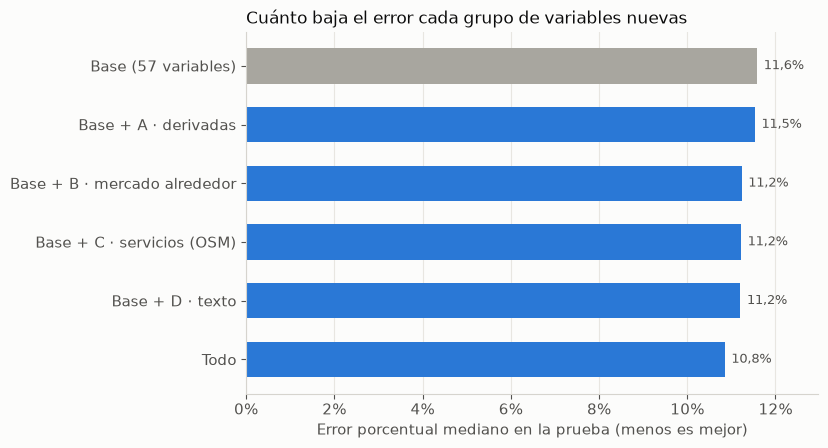

In [5]:
orden = ["Base (57 variables)", *[f"Base + {g}" for g in GRUPOS], "Todo"]
filas_g = res.loc[orden].iloc[::-1]
fig, ax = plt.subplots(figsize=(8.4, 4.6))
colores = [GRIS if k.startswith("Base (") else AZUL for k in filas_g.index]
ax.barh(filas_g.index, filas_g["MdAPE"], height=0.6, color=colores)
for i, v in enumerate(filas_g["MdAPE"]):
    ax.text(v + 0.0015, i, pct(v), va="center", fontsize=9, color=TINTA_2)
ax.set_xlim(0, filas_g["MdAPE"].max() * 1.12)
ax.xaxis.set_major_locator(plt.MultipleLocator(0.02))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Error porcentual mediano en la prueba (menos es mejor)")
ax.set_title("Cuánto baja el error cada grupo de variables nuevas", loc="left", fontsize=12, color=TINTA)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3. Qué pesa en el modelo con todo

Importancia por permutación (5.000 avisos de prueba), agrupando las variables que dicen lo mismo.

In [6]:
_, modelo, Xp = lightgbm(VARIANTES["Todo"], ajuste, validacion, prueba, devolver_modelo=True)
rng = np.random.default_rng(mp.SEMILLA)
m_idx = rng.choice(len(prueba), size=5000, replace=False)
Xm, ym = Xp.iloc[m_idx], y[prueba][m_idx]
base_err = np.median(mp.error(modelo.predict(Xm), ym))
limpio = lambda c: c.replace(":", "_").replace(" ", "_")
bloques = {
    "ubicación (coordenadas, barrio, zona, comuna, ciudad, depto.)": ["latitud", "longitud", "departamento"] + [f"te_{c}" for c in TE.columns],
    "área": ["m2", "m2_construido", "m2_terreno"],
    "estrato": ["estrato"],
    "resto de la ficha": [c for c in X.columns if c not in ("latitud", "longitud", "departamento", "m2", "m2_construido", "m2_terreno", "estrato") and not c.startswith("am: ")],
    "amenidades (40)": [c for c in X.columns if c.startswith("am: ")],
    **{g: list(D.columns) for g, D in GRUPOS.items()},
}
imp = {}
for nombre, cols in bloques.items():
    Xq = Xm.copy()
    orden_p = rng.permutation(len(Xq))
    for c in map(limpio, cols):          # conserva el tipo (las categóricas siguen siendo category)
        Xq[c] = pd.Series(Xq[c].to_numpy()[orden_p], index=Xq.index, dtype=Xq[c].dtype)
    imp[nombre] = np.median(mp.error(modelo.predict(Xq), ym)) - base_err
imp = pd.Series(imp).sort_values(ascending=False)
imp.map(lambda v: f"{v * 100:+.1f} pts").to_frame("error adicional al desordenarlo")

,error adicional al desordenarlo
área,+5.6 pts
resto de la ficha,+5.1 pts
"ubicación (coordenadas, barrio, zona, comuna, ciudad, depto.)",+4.6 pts
B · mercado alrededor,+4.3 pts
D · texto,+3.8 pts
estrato,+2.9 pts
A · derivadas,+1.3 pts
C · servicios (OSM),+1.1 pts
amenidades (40),+0.5 pts


In [7]:
# Las 20 variables nuevas más usadas por el modelo (ganancia acumulada en los árboles)
ganancia = pd.Series(modelo.booster_.feature_importance("gain"), index=modelo.booster_.feature_name())
nuevas_cols = {limpio(c): g for g, D in GRUPOS.items() for c in D.columns}
top = ganancia[ganancia.index.isin(nuevas_cols)].sort_values(ascending=False).head(20)
(top / ganancia.sum()).map(pct).to_frame("parte de la ganancia total").assign(grupo=[nuevas_cols[c] for c in top.index])

,parte de la ganancia total,grupo
med_vecinos_10,"30,7%",B · mercado alrededor
txt_puntaje,"17,5%",D · texto
med_vecinos_30,"16,1%",B · mercado alrededor
m2_por_hab,"2,3%",A · derivadas
banos_por_hab,"0,9%",A · derivadas
largo_descripcion,"0,7%",A · derivadas
oferta_500m,"0,6%",B · mercado alrededor
dist_vecinos_10,"0,6%",B · mercado alrededor
dist_vecinos_30,"0,6%",B · mercado alrededor
dist_transporte_masivo_km,"0,6%",C · servicios (OSM)


## 4. Por tipo y por ciudad

In [8]:
cols = ["Base (57 variables)", "Todo"]
t = a.iloc[prueba][["tipo", "ciudad"]].assign(**{k: errores[k] for k in cols})
por_tipo = t.groupby("tipo")[cols].median().assign(avisos=t.groupby("tipo").size())
display(por_tipo.style.format({**{c: pct for c in cols}, "avisos": mil}))
top_c = t["ciudad"].value_counts().head(10).index
por_ciudad = t[t["ciudad"].isin(top_c)].groupby("ciudad")[cols].median().loc[top_c].assign(avisos=t["ciudad"].value_counts().loc[top_c])
por_ciudad.style.format({**{c: pct for c in cols}, "avisos": mil})

,Base (57 variables),Todo,avisos
tipo,,,
Apartaestudio,"9,8%","9,6%",826
Apartamento,"10,0%","9,2%",15.513
Casa,"16,0%","15,1%",8.192


,Base (57 variables),Todo,avisos
ciudad,,,
Bogotá,"10,6%","9,7%",5.953
Medellín,"12,0%","11,2%",2.931
Cali,"12,0%","11,6%",1.741
Barranquilla,"12,6%","12,1%",1.325
Envigado,"10,4%","9,9%",1.140
Cartagena,"15,2%","13,8%",906
Manizales,"12,0%","11,5%",779
Pereira,"11,7%","11,1%",705
Santa marta,"13,3%","11,9%",585


## 5. Validación temporal y el mejor ensamble

Lo más cercano al uso real: entrenar con lo publicado antes del 1 de octubre y predecir lo publicado
después. Las variables fuera de pliegue se **recalculan** con esa partición (referencia = lo anterior a
octubre). Se compara la base con todo, en LightGBM y en el ensamble XGBoost + LightGBM (el mejor de la
comparación de modelos).

In [9]:
from xgboost import XGBRegressor

XGB = dict(n_estimators=10000, learning_rate=0.03, max_depth=8, min_child_weight=5, subsample=0.8, colsample_bytree=0.7,
           reg_lambda=1.0, tree_method="hist", enable_categorical=True, max_cat_to_onehot=1, early_stopping_rounds=200,
           n_jobs=-1, random_state=mp.SEMILLA)


def xgboost(Xb, ajuste, validacion, prueba):
    Xa, Xv, Xp = con_te(Xb, ajuste, validacion, prueba)
    m = XGBRegressor(**XGB)
    m.fit(Xa, y[ajuste], eval_set=[(Xv, y[validacion])], verbose=False)
    return m.predict(Xp)


t_tr, t_te = mp.particion_temporal(a, grupo)
t_aj, t_va = mp.subparticion(t_tr, grupo)
G_t = nuevas(t_aj, np.concatenate([t_va, t_te]))
variantes_t = {"Base (57 variables)": X, "Todo": pd.concat([X, *G_t.values()], axis=1)}
filas = []
for nombre, Xb in variantes_t.items():
    p_l = lightgbm(Xb, t_aj, t_va, t_te)
    p_x = xgboost(Xb, t_aj, t_va, t_te)
    filas.append(mp.metricas(mp.error(p_l, y[t_te])) | {"modelo": "LightGBM", "variables": nombre})
    filas.append(mp.metricas(mp.error((p_l + p_x) / 2, y[t_te])) | {"modelo": "Ensamble XGBoost + LightGBM", "variables": nombre})
print(f"Entrenamiento: {mil(len(t_tr))} avisos publicados antes del 1-oct · prueba: {mil(len(t_te))} publicados después")
res_t = pd.DataFrame(filas).set_index(["modelo", "variables"])
res_t.style.format(FORMATO)

Entrenamiento: 106.008 avisos publicados antes del 1-oct · prueba: 14.459 publicados después


,,MdAPE,±10%,±20%,avisos
modelo,variables,,,,
LightGBM,Base (57 variables),"10,8%","46,8%","75,6%",14.459
Ensamble XGBoost + LightGBM,Base (57 variables),"10,8%","47,1%","75,9%",14.459
LightGBM,Todo,"10,2%","49,4%","77,7%",14.459
Ensamble XGBoost + LightGBM,Todo,"10,1%","49,8%","77,8%",14.459


In [10]:
# El ensamble con todo, también en la partición por inmueble (para comparar con el 11,4% de la comparación)
p_l = lightgbm(VARIANTES["Todo"], ajuste, validacion, prueba)
p_x = xgboost(VARIANTES["Todo"], ajuste, validacion, prueba)
p_xb = xgboost(X, ajuste, validacion, prueba)
p_lb = lightgbm(X, ajuste, validacion, prueba)
pd.DataFrame({
    "Ensamble, base": mp.metricas(mp.error((p_lb + p_xb) / 2, y[prueba])),
    "Ensamble, todo": mp.metricas(mp.error((p_l + p_x) / 2, y[prueba])),
}).T.style.format(FORMATO)

,MdAPE,±10%,±20%,avisos
"Ensamble, base","11,4%","44,6%","72,7%",24.531
"Ensamble, todo","10,7%","47,4%","75,0%",24.531


## 6. Conclusiones (estado del 26-oct-2026)

| Variante (LightGBM) | Error mediano | Frente a la base (IC 95%) |
|---|---|---|
| Base (57 variables) | 11,6% | — |
| + A · derivadas | 11,5% | no se distingue |
| + B · mercado alrededor | 11,2% | −0,35 pts (−0,49 a −0,22) |
| + C · servicios OSM | 11,2% | −0,37 pts (−0,51 a −0,23) |
| + D · texto | 11,2% | −0,38 pts (−0,54 a −0,23) |
| Todo | 10,8% | −0,73 pts (−0,91 a −0,56) |
| **Todo menos A** | **10,7%** | **−0,83 pts (−0,99 a −0,66)** |

1. **Las variables nuevas valen más que cambiar de algoritmo.** Juntas bajan el error ~0,8 puntos; pasar de
   HistGradientBoosting al ensamble había bajado ~0,5. En avisos nuevos de octubre: de 10,8% a **10,1%**
   (ensamble) y la proporción dentro de ±10% sube de 47% a 50%.
2. **B, C y D aportan cada uno algo propio**: quitar cualquiera del conjunto completo sube el error
   0,2–0,3 puntos. **A (derivadas) no aporta** lo que no traigan ya los demás; sin ella el resultado es
   igual o un poco mejor. Se deja fuera.
3. **Lo que más pesa de lo nuevo:** la mediana del precio/m² de los 10 y 30 vecinos del mismo tipo (los
   "comparables" como variable) y el puntaje del texto. Los servicios de OSM aportan poco cada uno, pero
   juntos cuentan, con la distancia al transporte masivo y a vías principales entre los primeros.
4. **Mejora en todas partes:** apartamentos de 10,0% a 9,2%, casas de 16,0% a 15,1%, Bogotá de 10,6% a 9,7%.
   En **Cali** mejora menos (12,0% → 11,6%), coherente con que su cobertura en OSM es más pobre.
5. **Una trampa que se corrigió:** la primera versión del puntaje del texto leía los números de la
   descripción (que a menudo incluye el precio) y palabras como "urgente" o "negociable". Con eso el
   texto parecía aportar −0,52 puntos; limpio aporta −0,38. Lo que se quitó era el modelo copiando el
   precio pedido o aprendiendo "quién vende barato", no estimando el valor.

**Decisión para el modelo de producción:** base + **B · mercado alrededor** + **C · servicios** +
**D · texto** (sin A), con LightGBM o el ensamble XGBoost + LightGBM. Error mediano esperado: ~10,7% en la
partición por inmueble y ~10,1% en avisos nuevos.

**Próximos pasos:**
1. Llevar esta configuración a `src/modelo_precio.py` como un entrenamiento reproducible (función `entrenar`
   con las variables elegidas) y repetir la comparación con la alerta de Cali.
2. Mejorar Cali: revisar la cobertura de OSM (estaciones del MIO, parques, colegios) o completar con
   datos de la IDESC de la Alcaldía.
3. Casas: el área sigue siendo el punto débil (E4); separar lote y construcción desde el texto.
4. Más adelante: *embeddings* de la descripción con un modelo de lenguaje en lugar de TF-IDF.